# Visualização exploratória

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_04/03_visualizacao_exploratoria.ipynb)

![Cinco tipos de pergunta são ligados a barras, histograma e boxplot, dispersão, pontos e linha, ou barras de termos.](https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_04/imagens/03_escolha_grafico.svg?raw=1)

Gráficos são argumentos. Comece pela pergunta e pela escala conceitual da
variável. Toda figura terá título, eixos, unidades, descrição e tabela
equivalente. Os gráficos abaixo são calculados com Python a partir da base
fictícia; não constituem evidência histórica.

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_04'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente preparado em: /content/disciplina_computacao_aplicada_humanidades_digitais/unidade_04


In [2]:
import re
from collections import Counter

import pandas as pd
import sys
from pathlib import Path
from IPython.display import display
sys.path.insert(0, str(Path.cwd())) if str(Path.cwd()) not in sys.path else None
from graficos import barras_categorias, barras_horizontais, dispersao, histograma_boxplot, serie_temporal

dados = pd.read_csv("dados/documentos.csv")

O mapa anterior relaciona pergunta, escala e família gráfica. Começaremos pelo
caso mais simples: comparar categorias que já foram resumidas por frequências no
Notebook 01.

## Barras — categorias

As barras respondem a uma comparação entre categorias. Neste conjunto didático,
cada tema possui seis documentos: a igualdade foi construída deliberadamente e
não representa equilíbrio histórico. A tabela devolvida pelo código torna os
valores e o denominador auditáveis.

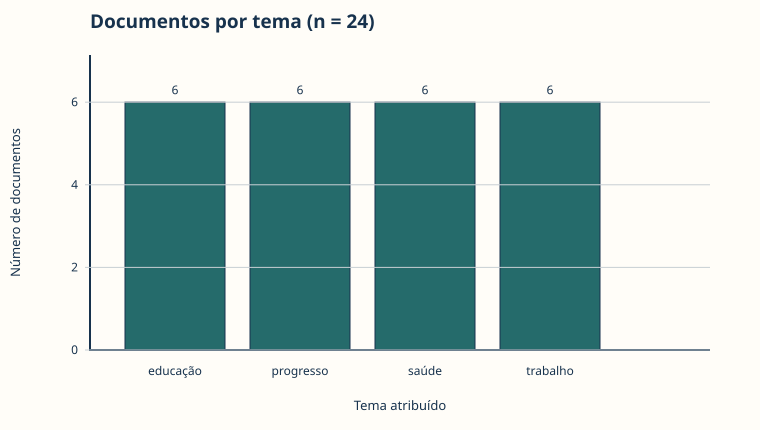

,documentos
tema,
educação,6
progresso,6
saúde,6
trabalho,6


In [3]:
tabela_temas = dados["tema"].value_counts().sort_index().rename("documentos").to_frame()
display(barras_categorias(
    tabela_temas.index.tolist(), tabela_temas["documentos"].tolist(),
    "Documentos por tema (n = 24)", "Tema atribuído", "Número de documentos",
    "Quatro barras de mesma altura mostram seis documentos em cada tema.",
))
tabela_temas

As barras anteriores representam categorias separadas. Para uma variável
quantitativa, porém, a posição dos valores e os intervalos entre eles importam;
por isso passamos a representações da distribuição.

## Histograma e boxplot — distribuições

Se os limites dos intervalos são $b_0,b_1,\ldots,b_J$, a altura da barra $j$
é a quantidade de valores dentro daquele intervalo:

$$
h_j=\sum_{i=1}^{n}\mathbf{1}(b_{j-1}<x_i\leq b_j).
$$

Alterar os limites $b_j$ pode mudar a forma visível da distribuição, mesmo sem
alterar os documentos. O boxplot aplica a regra de 1,5 IQR: os whiskers terminam
nos valores não extremos e D023 aparece como ponto separado. A tabela informa os
intervalos e o resumo numérico equivalentes.

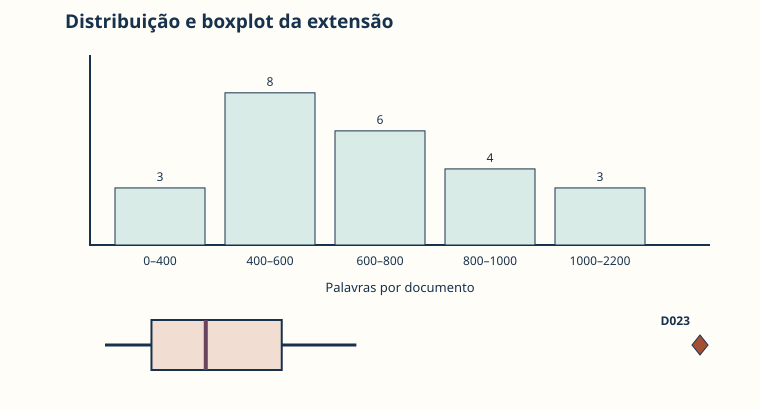

(palavras
 (0, 400]        3
 (400, 600]      8
 (600, 800]      6
 (800, 1000]     4
 (1000, 2200]    3
 Name: documentos, dtype: int64,
 count      24.000000
 mean      701.583333
 std       372.541205
 min       320.000000
 25%       459.000000
 50%       621.500000
 75%       848.750000
 max      2100.000000
 Name: palavras, dtype: float64)

In [4]:
faixas = [0, 400, 600, 800, 1000, 2200]
tabela_intervalos = dados.groupby(pd.cut(dados["palavras"], faixas), observed=False).size().rename("documentos")
display(histograma_boxplot(
    dados["palavras"].tolist(), faixas, dados["id_documento"].tolist()
))
tabela_intervalos, dados["palavras"].describe()

Histograma e boxplot descrevem uma variável quantitativa por vez. Quando a
pergunta envolve como duas quantidades variam conjuntamente, cada documento deve
ser localizado por um par de coordenadas.

## Dispersão — relação entre quantitativas

Cada ponto representa um documento. Forma e cor distinguem os gêneros, enquanto
a tabela mantém os pares e IDs disponíveis. D023 deve ser inspecionado; o padrão
visual entre páginas e palavras não demonstra causalidade.

In [ ]:
display(dispersao(
    dados["paginas"].tolist(), dados["palavras"].tolist(),
    dados["genero"].tolist(), dados["id_documento"].tolist(),
    "Páginas e extensão dos documentos", "Páginas", "Palavras",
))
dados[["id_documento", "genero", "paginas", "palavras"]]

O gráfico de dispersão não exige uma ordem substantiva entre os casos. Quando
uma das variáveis é o tempo, a sequência cronológica acrescenta informação, mas
também pode sugerir uma continuidade que o corpus não sustenta.

## Série temporal

Se $n_t$ documentos pertencem ao ano $t$, a média anual representada pela
linha é:

$$
\bar{x}_t=\frac{1}{n_t}\sum_{i:\,\mathrm{ano}_i=t}x_i.
$$

A fórmula torna visível o denominador anual. Mostraremos os documentos individuais
junto da média, pois cada ano contém apenas dois casos. D023 eleva a média de 1900;
a linha reflete a composição do corpus e não demonstra mudança histórica contínua.

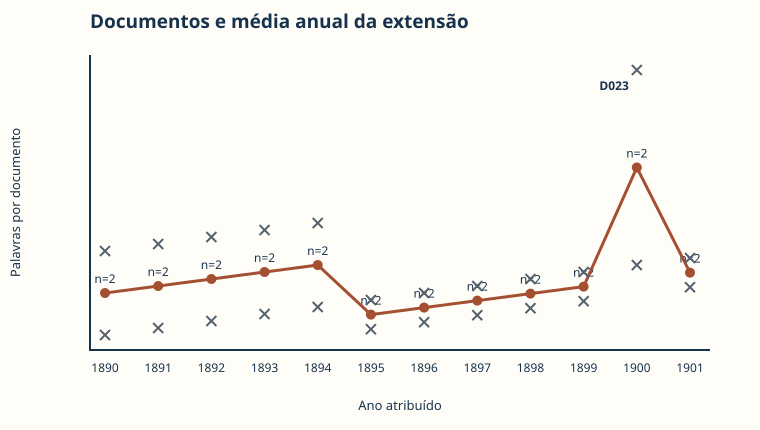

,n,media
ano,,
1890,2,602.0
1891,2,649.0
1892,2,696.0
1893,2,743.0
1894,2,790.0
1895,2,457.0
1896,2,504.0
1897,2,551.0
1898,2,598.0


In [5]:
resumo_anual = dados.groupby("ano")["palavras"].agg(n="size", media="mean")
display(serie_temporal(
    dados["ano"].tolist(), dados["palavras"].tolist(), dados["id_documento"].tolist(),
    resumo_anual["media"].to_dict(), resumo_anual["n"].to_dict(),
))
resumo_anual

Até aqui visualizamos metadados e medidas documentais. O mesmo princípio —
escolher uma forma coerente e manter uma tabela equivalente — vale para os
resultados textuais produzidos no Notebook 02.

## Frequências textuais

Barras preservam valores melhor que nuvem de palavras. A tabela informa as
frequências e o denominador deve ser lido junto das regras de tokenização e da
lista de stopwords.

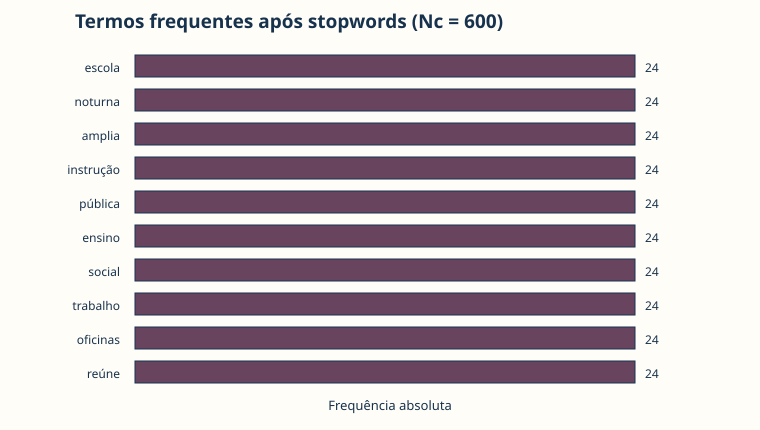

,termo,frequencia
0,escola,24
1,noturna,24
2,amplia,24
3,instrução,24
4,pública,24
5,ensino,24
6,social,24
7,trabalho,24
8,oficinas,24
9,reúne,24


In [6]:
tokens = re.findall(r"[a-záàâãéêíóôõúç]+", " ".join(dados["texto"]).lower())
stopwords = {"a", "o", "e", "de", "do", "da", "como", "em", "nas", "um", "uma", "também"}
tokens_conteudo = [token for token in tokens if token not in stopwords]
top = Counter(tokens_conteudo).most_common(10)
tabela_termos = pd.DataFrame(top, columns=["termo", "frequencia"])
ordenada = tabela_termos.sort_values("frequencia")
display(barras_horizontais(
    ordenada["termo"].tolist(), ordenada["frequencia"].tolist(),
    f"Termos frequentes após stopwords (Nc = {len(tokens_conteudo)})",
    "Dez barras horizontais ordenadas mostram frequências absolutas dos tokens de conteúdo.",
))
tabela_termos

---

## Aplicação ao projeto — discursos de posse presidencial, 1985–2023

Base construída nas Unidades 2 e 3 (não o corpus fictício da unidade). Entradas em
`dados/derivados/`:

| Arquivo | Unidade da linha | n |
|---|---|---|
| `documentos_processaveis.csv` | um discurso de posse | 12 |
| `discursos_trechos.csv` | um trecho com ocorrência de `liberdade(s)` | 49 |
| `coocorrencias.csv` | termo de conteúdo na janela ±5 do alvo, por discurso | 225 |
| `motivos_exclusao.csv` | documento descartado | 2 |

**Proveniência.** Onze transcrições vêm do repositório `estadao/discurso-de-posse-presidentes`
(até 2003 derivado de *Palavra de Presidente*, de João Bosco Bezerra Bonfim; depois, acervo
do Estadão e Biblioteca da Presidência). O discurso de 2023 foi fornecido pelo autor do
projeto.

**Desvios em relação ao protocolo**, registrados em `log_transformacoes.csv`:

1. só o arquivo de 2023 preserva quebras de parágrafo; para manter a unidade comparável,
   todos os documentos foram segmentados por **sentença**, e o trecho é a sentença-alvo
   mais uma sentença à esquerda e uma à direita (`posicao_sentenca` permite recompor);
2. `partido` permanece nulo, com `razao_partido_ausente` — não verificado em fonte documental;
3. Sarney (1985) e Temer (2016) entram como **casos limítrofes**: nenhum proferiu o texto
   na sessão solene de posse no Congresso. Tancredo Neves (1985) foi excluído por não ter
   tomado posse.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

docs = pd.read_csv("dados/derivados/documentos_processaveis.csv").sort_values("ano")
trechos = pd.read_csv("dados/derivados/discursos_trechos.csv")
coocorrencias = pd.read_csv("dados/derivados/coocorrencias.csv")

CURTO = {"José Sarney": "Sarney", "Fernando Collor de Mello": "Collor",
         "Itamar Franco": "Itamar", "Fernando Henrique Cardoso": "FHC",
         "Luiz Inácio Lula da Silva": "Lula", "Dilma Rousseff": "Dilma",
         "Michel Temer": "Temer", "Jair Bolsonaro": "Bolsonaro"}
docs["curto"] = docs["presidente"].map(CURTO)
rotulos = docs["ano"].astype(str) + "\n" + docs["curto"]

docs[["ano", "presidente", "palavras", "ocorrencias_liberdade",
      "taxa_liberdade_mil", "n_trechos", "ttr"]].round(3)

,ano,presidente,palavras,ocorrencias_liberdade,taxa_liberdade_mil,n_trechos,ttr
0,1985,José Sarney,3860,19,4.922,16,0.370
1,1990,Fernando Collor de Mello,5917,9,1.521,8,0.335
2,1992,Itamar Franco,614,0,0.000,0,0.526
3,1995,Fernando Henrique Cardoso,3255,8,2.458,7,0.378
4,1999,Fernando Henrique Cardoso,2703,1,0.370,1,0.401
5,2003,Luiz Inácio Lula da Silva,3881,0,0.000,0,0.371
6,2007,Luiz Inácio Lula da Silva,3833,0,0.000,0,0.359
7,2011,Dilma Rousseff,3828,4,1.045,4,0.333
8,2015,Dilma Rousseff,4523,3,0.663,2,0.319
9,2016,Michel Temer,2741,1,0.365,1,0.370


### Figura 1 — barras: ocorrências por discurso

**Pergunta:** em quais discursos o termo aparece, e em quais não aparece?

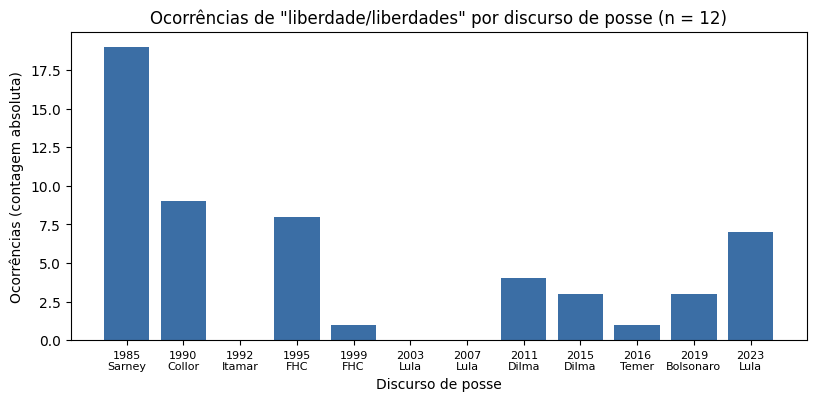

,ano,curto,ocorrencias_liberdade,n_trechos,razao_ausencia
0,1985,Sarney,19,16,NaN
1,1990,Collor,9,8,NaN
2,1992,Itamar,0,0,pronunciamento sem menção ao termo
3,1995,FHC,8,7,NaN
4,1999,FHC,1,1,NaN
5,2003,Lula,0,0,pronunciamento sem menção ao termo
6,2007,Lula,0,0,pronunciamento sem menção ao termo
7,2011,Dilma,4,4,NaN
8,2015,Dilma,3,2,NaN
9,2016,Temer,1,1,NaN


In [2]:
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.bar(rotulos, docs["ocorrencias_liberdade"], color="#3b6ea5")
ax.set_title('Ocorrências de "liberdade/liberdades" por discurso de posse (n = 12)')
ax.set_xlabel("Discurso de posse"); ax.set_ylabel("Ocorrências (contagem absoluta)")
ax.tick_params(axis="x", labelsize=8)
plt.show()

docs[["ano", "curto", "ocorrencias_liberdade", "n_trechos", "razao_ausencia"]]

| Item | Conteúdo |
|---|---|
| **Por que barras** | a pergunta compara unidades discretas; a barra de altura zero torna a ausência visível, o que uma linha interpolaria |
| **Escala** | `ocorrencias_liberdade` é numérica de razão (zero = ausência); eixo x categórico, ordenado no tempo |
| **Descrição alternativa** | barras verticais, um discurso por barra em ordem cronológica; 1985 é a mais alta (19); 1992, 2003 e 2007 têm altura zero |
| **Padrão** | 1985 concentra 19 das 55 ocorrências do corpus; 3 dos 12 discursos não usam o termo |
| **Caso** | Lula 2003 e 2007 — dois discursos longos (3.881 e 3.833 palavras) com zero ocorrências, do mesmo presidente que em 2023 registra 7 |
| **Limite** | contagem absoluta não é comparável entre textos de tamanhos diferentes; ausência do lexema não é ausência do tema (Lula 2007 usa `livre` 3×) |
| **Hipótese** | o termo é acionado em conjunturas de disputa sobre o regime, não como vocabulário permanente do gênero de posse |

### Figura 2 — histograma e boxplot: extensão dos discursos

**Pergunta:** os discursos são comparáveis em tamanho? A resposta condiciona a leitura da Figura 1.

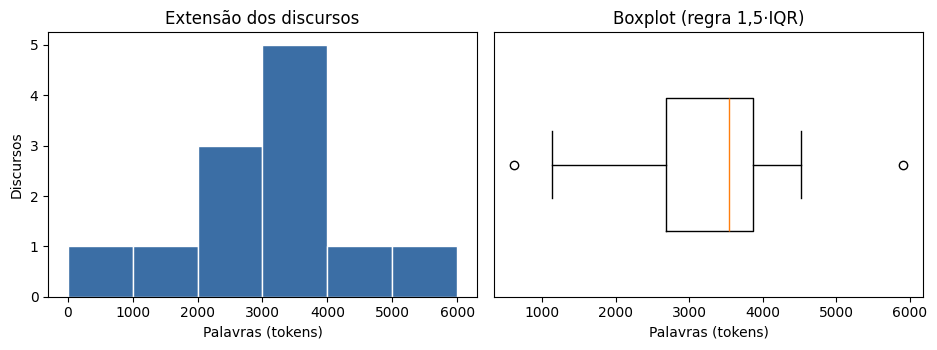

Q1=2686  Q3=3865  IQR=1180  limites=[916, 5635]


,id_doc,palavras
1,DISCURSO_1990_COLLOR,5917
2,DISCURSO_1992_ITAMAR,614


In [3]:
q1, q3 = docs["palavras"].quantile(.25), docs["palavras"].quantile(.75)
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 3.6))
a1.hist(docs["palavras"], bins=range(0, 7000, 1000), color="#3b6ea5", edgecolor="white")
a1.set_title("Extensão dos discursos")
a1.set_xlabel("Palavras (tokens)"); a1.set_ylabel("Discursos")
a2.boxplot(docs["palavras"], vert=False, widths=.5)
a2.set_title("Boxplot (regra 1,5·IQR)")
a2.set_xlabel("Palavras (tokens)"); a2.set_yticks([])
plt.tight_layout(); plt.show()

print(f"Q1={q1:.0f}  Q3={q3:.0f}  IQR={iqr:.0f}  "
      f"limites=[{limite_inferior:.0f}, {limite_superior:.0f}]")
docs.loc[docs["palavras"].lt(limite_inferior) | docs["palavras"].gt(limite_superior),
         ["id_doc", "palavras"]]

| Item | Conteúdo |
|---|---|
| **Por que histograma e boxplot** | a pergunta é sobre a forma da distribuição de uma variável quantitativa; o boxplot acrescenta a regra explícita de 1,5·IQR para localizar casos a inspecionar |
| **Escala** | `palavras` é numérica de razão, discreta |
| **Tabela** | Q1 = 2.686, Q3 = 3.865, IQR = 1.180, limites [916; 5.635]; fora deles, Collor (5.917) e Itamar (614) |
| **Descrição alternativa** | histograma com maior barra na faixa 3.000–4.000 palavras e cauda dos dois lados; boxplot com dois pontos fora dos whiskers |
| **Padrão** | os discursos variam de 614 a 5.917 palavras, quase 10× |
| **Caso** | Itamar 1992 (614 palavras) — o zero da Figura 1 tem base textual mínima |
| **Limite** | os dois extremos são de natureza documental distinta (Itamar assume em contexto de impeachment) e não devem ser excluídos automaticamente |
| **Hipótese** | parte da variação da Figura 1 é efeito de extensão, não de escolha lexical — o que exige normalização |

### Figura 3 — série temporal: taxa por 1.000 palavras

**Pergunta:** controlada a extensão, como a presença do termo se distribui no tempo?

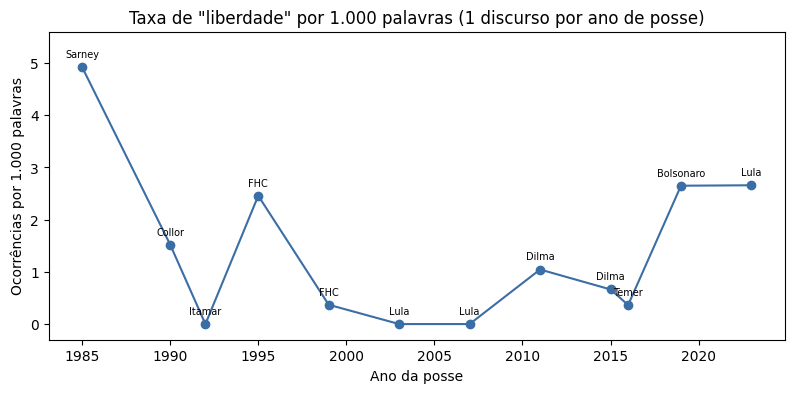

,ano,curto,palavras,ocorrencias_liberdade,taxa_liberdade_mil
0,1985,Sarney,3860,19,4.922
1,1990,Collor,5917,9,1.521
2,1992,Itamar,614,0,0.000
3,1995,FHC,3255,8,2.458
4,1999,FHC,2703,1,0.370
5,2003,Lula,3881,0,0.000
6,2007,Lula,3833,0,0.000
7,2011,Dilma,3828,4,1.045
8,2015,Dilma,4523,3,0.663
9,2016,Temer,2741,1,0.365


In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(docs["ano"], docs["taxa_liberdade_mil"], marker="o", color="#3b6ea5")
for _, r in docs.iterrows():
    ax.annotate(r["curto"], (r["ano"], r["taxa_liberdade_mil"]),
                textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7)
ax.set_title('Taxa de "liberdade" por 1.000 palavras (1 discurso por ano de posse)')
ax.set_xlabel("Ano da posse"); ax.set_ylabel("Ocorrências por 1.000 palavras")
ax.set_ylim(-.3, 5.6)
plt.show()

docs[["ano", "curto", "palavras", "ocorrencias_liberdade", "taxa_liberdade_mil"]].round(3)

| Item | Conteúdo |
|---|---|
| **Por que série temporal** | a pergunta do projeto é sobre transformação ao longo do tempo, e a taxa corrige o viés de extensão diagnosticado na Figura 2 |
| **Escala** | taxa numérica de razão sobre eixo temporal discreto e irregular (anos de posse, não anos consecutivos) |
| **Tabela** | `taxa_liberdade_mil` por ano; denominador = `palavras` de cada discurso, um discurso por ponto |
| **Descrição alternativa** | linha com marcadores: pico em 1985 (4,92), zero em 1992, repique em 1995 (2,46), platô próximo de zero entre 1999 e 2007, subida a 2,65 em 2019 e 2,66 em 2023 |
| **Padrão** | forma em U: valores altos nas pontas (1985 e 2019–2023) e vale entre 1999 e 2007 |
| **Caso** | 2019 e 2023 quase empatam na taxa (2,650 e 2,659) com contagens distintas (3 e 7), porque Bolsonaro fala 1.132 palavras e Lula 2.633 |
| **Limite** | cada ponto é **um único discurso**, não uma média anual; a linha liga anos não contíguos e sugere continuidade que o corpus não sustenta |
| **Hipótese** | há dois picos de uso com sentidos possivelmente opostos — 1985 e 2019–2023 — e não uma tendência monotônica |

### Figura 4 — frequências textuais: coocorrentes por período

**Pergunta:** com que campo semântico o termo aparece associado em cada período?

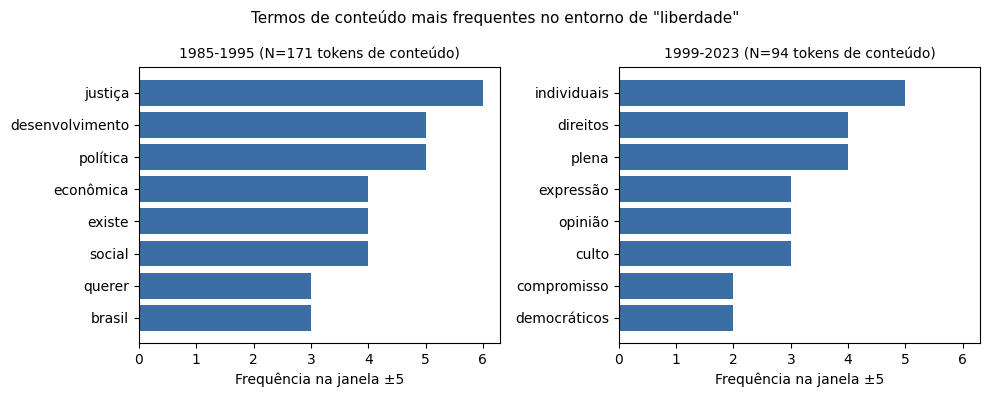

,periodo,termo_coocorrente,frequencia
66,1985-1995,justiça,6
24,1985-1995,desenvolvimento,5
89,1985-1995,política,5
33,1985-1995,econômica,4
44,1985-1995,existe,4
117,1985-1995,social,4
102,1985-1995,querer,3
7,1985-1995,brasil,3
161,1999-2023,individuais,5
151,1999-2023,direitos,4


In [5]:
coocorrencias["periodo"] = coocorrencias["ano"].map(
    lambda a: "1985-1995" if a <= 1995 else "1999-2023"
)
tabela = (coocorrencias.groupby(["periodo", "termo_coocorrente"])["frequencia"]
          .sum().reset_index().sort_values("frequencia", ascending=False))
denominadores = coocorrencias.groupby("periodo")["frequencia"].sum()
top = {p: tabela[tabela["periodo"] == p].head(8) for p in ["1985-1995", "1999-2023"]}

fig, eixos = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
for eixo, periodo in zip(eixos, top):
    d = top[periodo].iloc[::-1]
    eixo.barh(d["termo_coocorrente"], d["frequencia"], color="#3b6ea5")
    eixo.set_title(f"{periodo} (N={int(denominadores[periodo])} tokens de conteúdo)",
                   fontsize=10)
    eixo.set_xlabel("Frequência na janela ±5")
fig.suptitle('Termos de conteúdo mais frequentes no entorno de "liberdade"', fontsize=11)
plt.tight_layout(); plt.show()

pd.concat([top["1985-1995"], top["1999-2023"]])

| Item | Conteúdo |
|---|---|
| **Por que barras horizontais** | comparam termos nomeados preservando o valor exato, ao contrário da nuvem de palavras, e o rótulo longo cabe no eixo y |
| **Escala** | frequência absoluta (razão) por termo nominal |
| **Tabela** | oito termos mais frequentes por período; denominadores N = 171 (1985–1995) e N = 94 (1999–2023) tokens de conteúdo na janela ±5 |
| **Descrição alternativa** | dois painéis de barras horizontais; à esquerda encabeçam `justiça`, `desenvolvimento`, `política`; à direita, `individuais`, `direitos`, `plena`, `expressão`, `opinião`, `culto` |
| **Padrão** | o entorno migra de vocabulário socioeconômico e de regime para vocabulário de direitos individuais, culto, opinião e expressão |
| **Caso** | Dilma 2011 — `liberdades individuais`, `liberdade de culto e de religião`, `liberdade de imprensa e de opinião` em sequência; boa parte do painel direito vem desse discurso e de 2023 |
| **Limite** | frequências baixíssimas (máximo 6); a janela ±5 corta sintagmas, `plena` é adjetivo, e a partição em dois períodos é decisão minha, não corte da fonte |
| **Hipótese** | a ressignificação ocorre menos na frequência do que no complemento do termo — de liberdade como condição do regime para liberdade como lista de direitos enumerados |

### Retorno aos trechos

Nenhuma figura substitui a leitura. Amostra de sentenças-alvo:

In [6]:
amostra = trechos[trechos["id_doc"].isin(
    ["DISCURSO_1985_SARNEY", "DISCURSO_2011_DILMA", "DISCURSO_2023_LULA"]
)].groupby("id_doc").head(3)
for linha in amostra.itertuples():
    print(f"[{linha.trecho_id}] {linha.sentenca_alvo[:150]}")

[DISCURSO_1985_SARNEY_SENT_003] Respira-se liberdade.
[DISCURSO_1985_SARNEY_SENT_057] Nossos objetivos passam por cinco pontos fundamentais: Liberdade Desenvolvimento Opção social Identidade cultural Soberania e Independência A política
[DISCURSO_1985_SARNEY_SENT_058] A liberdade é um legado de Deus.
[DISCURSO_2011_DILMA_SENT_033] Uma democracia vibrante e moderna, plena de compromisso social, liberdade política e criatividade.
[DISCURSO_2011_DILMA_SENT_152] Reafirmo meu compromisso inegociável com a garantia plena das liberdades individuais;
[DISCURSO_2011_DILMA_SENT_153] da liberdade de culto e de religião;
[DISCURSO_2023_LULA_SENT_005] as mais violentas ameaças à liberdade do voto, a mais abjeta campanha de mentiras e de ódio tramada para manipular e constranger o eleitorado.
[DISCURSO_2023_LULA_SENT_047] A outra, no individualismo, na negação da política, na destruição do Estado em nome de supostas liberdades individuais.
[DISCURSO_2023_LULA_SENT_048] A liberdade que sempre defende

## U04-A04 — Atividade — visualização exploratória

Produza barras, histograma/boxplot, dispersão ou tempo e frequência textual. Para
cada figura, entregue tabela, descrição alternativa, escala, padrão, caso, limite
e hipótese. Explique também por que o gráfico escolhido responde à pergunta.

**Minha análise:** cada figura acima é seguida da sua própria tabela de análise —
justificativa do tipo de gráfico, escala, tabela, descrição alternativa, padrão, caso,
limite e hipótese. Síntese:

**Quatro figuras selecionadas para o Notebook 04** — Figuras 1 a 4, nesta ordem:
presença, extensão, tempo normalizado e campo semântico. Cada uma responde à pergunta
que a anterior deixa aberta, e nenhuma repete o denominador da outra.

**Limite comum a todas** — n = 12 discursos, 55 ocorrências ao todo. Nenhuma figura
sustenta teste, tendência ou comparação inferencial: isso pertence à Unidade 5.